In [1]:
"""
Code to do exploratory data analysis (EDA) on model and observation
"""
import sys
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from lo_tools import plotting_functions as pfun
from lo_tools import Lfun

In [2]:
Ldir = Lfun.Lstart()
# read data in
in_dir = Ldir['parent'] / 'LPM_output' / 'obsmod'

In [3]:
# select data source
# model run choice
gtx = 'cas2k_v4_lo2b'
source = 'nceiCoastal' # source can be 'LineP', 'nceiCoastal', 'dfo1', 'NHL', 'nceiSalish', 'WOD', 'nceiPNW','SXS'

# data choices
otype = 'bottle'
# otype = 'ctd'

# where to put output figures
out_dir = Ldir['LOo'] / 'LO_bias_corr'/ 'plots' / otype

Lfun.make_dir(out_dir)
if  source == 'all' and otype == 'ctd':
    # yr_list = [str(year) for year in range(1998, 2023)]
    yr_list = [str(year) for year in range(2014, 2015)]   # good DO data starts at 1998
    print(yr_list)
elif  source == 'all' and otype == 'bottle':
    # yr_list = [str(year) for year in range(1993, 2023)]
    yr_list = [str(year) for year in range(1993, 2023)]
    print(yr_list)
elif source == 'LineP':
    yr_list = [str(year) for year in [1994, 1996, 1997, 1999] + list(range(2001, 2009)) + [2010] + list(range(2013, 2020))] # for lineP

elif source == 'nceiCoastal':
    yr_list = [str(year) for year in [2007, 2011, 2012, 2013,2016, 2017, 2021]]
elif source == 'NHL':
    yr_list = [str(year) for year in range(1997, 2022)]
elif source == 'SXS':
    yr_list = [str(year) for year in [2009]]
    print(yr_list)
elif source == 'HABRISE':
    yr_list = [str(year) for year in range(2003, 2007)]
elif source == 'Hake':
    yr_list = [str(year) for year in [2011,  2012, 2013, 2015]]
elif source == 'IPHC':
    yr_list = [str(year) for year in list(range(2009, 2019)) + [2022]]
else:
    yr_list = [str(year) for year in range(1993, 2022)]
    print(yr_list)

In [4]:
# check the folder
for year in yr_list:
    print(year)
    # specify input (created by process_multi_bottle.py)
    in_fn = in_dir / ('combined_' + otype + '_' + str(year)+'_' + gtx +'.p')
    df0_dict = pickle.load(open(in_fn, 'rb'))

2007
2011
2012
2013
2016
2017
2021


In [5]:
# ========= SET FILTERS =============================================

fil_dict = dict()  # dict to hold filter choices

# Set mask_salish to True to ignore stations in the Salish Sea
if source == 'nceiCoastal' or source == 'dfo1':
    fil_dict['mask_salish'] = False
    fil_dict['mask_coast'] = False
    fil_dict['clean_up'] = True
elif source == 'all':
    fil_dict['mask_salish'] = True
    fil_dict['mask_coast'] = False
    fil_dict['clean_up'] = True
    
# Set mask_coast to True to ignore stations OUTSIDE the Salish Sea
else:
    fil_dict['mask_salish'] = False
    fil_dict['mask_coast'] = False
    fil_dict['clean_up'] = True
if fil_dict['mask_salish'] and fil_dict['mask_coast']:
    print('Error: Too many spatial masks!')
    sys.exit()

In [6]:
 # start assembling some text for the plot that will include info about the filters
f_str = otype  + '\n' + yr_list[0] +'-'+ yr_list[-1] + '\n'# a string to put for info on the map
ff_str = otype + '_' + yr_list[0] +'-'+ yr_list[-1] + '_' + gtx # a string for the output .png file name
    # limit which sources to use
if source == 'all':
    # use df_dict as-is
    f_str += 'Source = all\n'
    ff_str += '_all'
else:
    # use just one source
    f_str += 'Source = ' + source + '\n'
    ff_str += '_' + source
    for gtxo in df0_dict.keys():
        df0_dict[gtxo] = df0_dict[gtxo][df0_dict[gtxo].source==source]
        # df0_dict[gtxo] = df0_dict[gtxo].loc[df0_dict[gtxo].source==source,:]

# plotting choices
testing = True
small = True # True for laptop size plot

2007
2011
2012
2013
2016
2017
2021


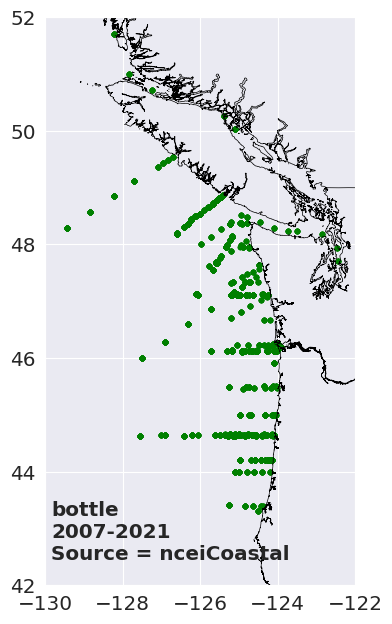

In [7]:
# plot all station map
# fig = plt.figure()
plt.close('all')

if small:
    fs = 12
    pfun.start_plot(figsize=(4,16), fs=fs)
else:
    fs = 14
    pfun.start_plot(figsize=(20,12), fs=fs)

fig = plt.figure()
ax = fig.add_subplot(1,1,1)
for year in yr_list:
    print(year)
    # specify input (created by process_multi_bottle.py)
    in_fn = in_dir / ('combined_' + otype + '_' + str(year)+'_' + gtx +'.p')
    df0_dict = pickle.load(open(in_fn, 'rb'))
    for gtxo in df0_dict.keys():
        df0_dict[gtxo] = df0_dict[gtxo][df0_dict[gtxo].source==source]
    if fil_dict['mask_salish']:
        for gtxo in df0_dict.keys():
            a = df0_dict[gtxo].copy()
            mask1 = (a.lat >= 46) & (a.lat < 49) & (a.lon > -124)
            mask2 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -125)
            mask3 = (a.lat >= 49.5) & (a.lat < 52) & (a.lon > -126)
            mask4 = (a.lat >= 50) & (a.lat < 52) & (a.lon > -128.5)
            mask5 = (a.lat >= 48.5) & (a.lat < 49.5) & (a.lon > -125.5)
            mask6 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -126.5)
            mask7 = (a.lat >= 51) & (a.lat < 52) & (a.lon > -128) & (a.lon < -126.5)
            a = a.loc[(~mask1) & (~mask2) & (~mask3) & (~mask4) & (~mask5) & (~mask6) & (~mask7), :]
            df0_dict[gtxo] = a

    df_dict = df0_dict.copy()
    df_dict['obs'].plot(x='lon',y='lat',style='.g',legend=False, ax=ax)

pfun.add_coast(ax)
ax.axis([-130,-122,42,52])
ax.tick_params(axis='both', labelsize=fs*1.2)
pfun.dar(ax)
ax.set_xlabel('')
ax.set_ylabel('')
ax.text(.02,0,f_str,fontsize = fs*1.2, va='bottom',transform=ax.transAxes,fontweight='bold')

# fig.tight_layout()
# ff_str += '_' + 'map'
fig.savefig(out_dir / (ff_str +'_' + 'map' + '.png'))

In [8]:
# PLOTTING setup

plt.close('all')

if small:
    fs = 12
    pfun.start_plot(figsize=(5,5), fs=fs)
else:
    fs = 14
    pfun.start_plot(figsize=(20,12), fs=fs)

NH4 = False
Chl = False

lim_dict = {'SA':(30,36),'CT':(0,20),'DO (uM)':(0,600),
            'NO3 (uM)':(0,50),'NH4 (uM)':(0,10),'DIN (uM)':(0,50),
            'DIC (uM)':(1600,2600),'TA (uM)':(1600,2600),'Chl (mg m-3)':(0,20)}
if NH4:
    vn_list = ['SA','CT','DO (uM)','NO3 (uM)','NH4 (uM)','DIN (uM)',
               'DIC (uM)', 'TA (uM)']#, 'Chl (mg m-3)']
    jj_list = [1,2,3,5,6,7,9,10,11] # indices for the data plots

elif Chl:
    vn_list = ['SA','CT','DO (uM)','NO3 (uM)',
               'DIC (uM)', 'TA (uM)', 'Chl (mg m-3)']
    jj_list = [1,2,3,5,6,7,9] # indices for the data plots    

elif otype == 'ctd':
    vn_list = ['SA','CT','DO (uM)']
    jj_list = [1,2,3] # indices for the data plots
    fs = 10
    pfun.start_plot(figsize=(12,4), fs=fs)
    
elif otype == 'bottle':
    vn_list = ['SA','CT','DO (uM)','NO3 (uM)',
               'DIC (uM)', 'TA (uM)']
    print(vn_list)
    jj_list = [1,2,3,4,5,6] # indices for the data plots
    print(f'subplot indices: {jj_list}')
    fs = 12
    """for NHL bottle only because it doesn't have NO3""" 
    # vn_list = ['SA','CT','DO (uM)',
    #            'DIC (uM)', 'TA (uM)']
    # jj_list = [1,2,3,5,6] # indices for the data plots
    # fs = 10
    pfun.start_plot(figsize=(11,6), fs=fs)

alpha = 0.3

depth_list = ['deep', 'shallow']
t_dict = dict(zip(depth_list,[.05,.15]))

['SA', 'CT', 'DO (uM)', 'NO3 (uM)', 'DIC (uM)', 'TA (uM)']
subplot indices: [1, 2, 3, 4, 5, 6]


2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021


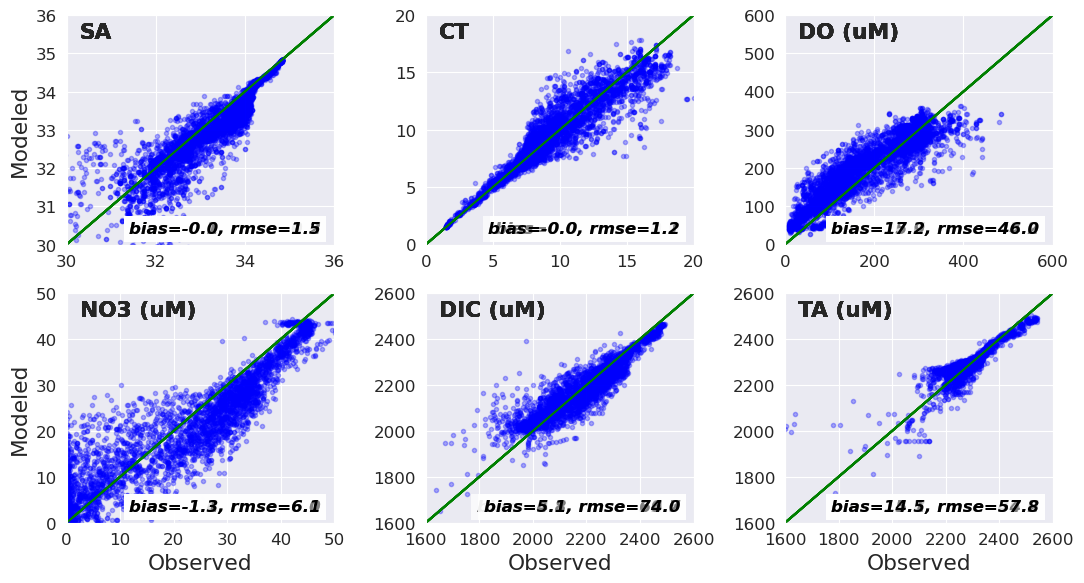

In [9]:
# plot 1:1 observation-model comparison
fig = plt.figure()
ax_dict = {}

for ii in range(len(vn_list)):
    jj = jj_list[ii]
    if otype == 'ctd':
        ax = fig.add_subplot(1,3,jj)
        ax_dict[ii] = ax
    else:
        ax = fig.add_subplot(2,3,jj)
        ax_dict[ii] = ax
    bias_list = []
    rmse_list = []
    for year in yr_list:
        print(year)
        # specify input (created by process_multi_bottle.py)
        in_fn = in_dir / ('combined_' + otype + '_' + str(year)+'_' + gtx +'.p')
        df0_dict = pickle.load(open(in_fn, 'rb'))
        for gtxo in df0_dict.keys():
            df0_dict[gtxo] = df0_dict[gtxo][df0_dict[gtxo].source==source]
        # ======== APPLY FILTERS ==================================
        if fil_dict['clean_up']:
            a = df0_dict['obs'].copy()
            if 'otype' == 'bottle':
                mask1 =  pd.isna(a['CT'])| pd.isna(a['SA'])| pd.isna(a['DO (uM)']) |(a['DO (uM)'] < 0) | (a['DO (uM)'] > 650) | (a['NO3 (uM)'] > 55)
                mask2 =  (a['CT'] < 5) & (a['DO (uM)'] > 200)
                mask3 =  (a['CT'] < 7) & (a['DO (uM)'] > 300)
            else:
                mask1 = pd.isna(a['CT'])| pd.isna(a['SA'])| pd.isna(a['DO (uM)']) | (a['DO (uM)'] < 0) | (a['DO (uM)'] > 650)
                mask2 =  (a['CT'] < 5) & (a['DO (uM)'] > 200)
                mask3 =  (a['CT'] < 7) & (a['DO (uM)'] > 300)
            mask = (~mask1) & (~mask2) & (~mask3)
            df0_dict['obs'] = a.loc[mask, :]
            df0_dict[gtx] = df0_dict[gtx].loc[mask, :]  # Apply mask to model as well

        if fil_dict['mask_salish']:
            for gtxo in df0_dict.keys():
                a = df0_dict[gtxo].copy()
                mask1 = (a.lat >= 46) & (a.lat < 49) & (a.lon > -124)
                mask2 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -125)
                mask3 = (a.lat >= 49.5) & (a.lat < 52) & (a.lon > -126)
                mask4 = (a.lat >= 50) & (a.lat < 52) & (a.lon > -128.5)
                mask5 = (a.lat >= 48.5) & (a.lat < 49.5) & (a.lon > -125.5)
                mask6 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -126.5)
                mask7 = (a.lat >= 51) & (a.lat < 52) & (a.lon > -128) & (a.lon < -126.5)
                a = a.loc[(~mask1) & (~mask2) & (~mask3) & (~mask4) & (~mask5) & (~mask6) & (~mask7), :]
                df0_dict[gtxo] = a

        # mask out Coastal Fields
        if fil_dict['mask_coast']:
            for gtxo in df0_dict.keys():
                a = df0_dict[gtxo].copy()
                mask1 = (a.lat >= 47) & (a.lat < 49) & (a.lon > -124)
                mask2 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -125)
                mask = (~mask1) & (~mask2)
                a = a.loc[~mask, :]
                df0_dict[gtxo] = a

        df_dict = df0_dict.copy()

        vn = vn_list[ii]
        x = df_dict['obs'][vn].to_numpy()
        y = df_dict[gtx][vn].to_numpy()
        ax.plot(x,y,marker='.',ls='',color='b', alpha=alpha)
        if (not np.isnan(x).all()) and (not np.isnan(y).all()) and (len(x) > 0) and (len(y) > 0):
            bias = np.nanmean(y-x)
            rmse = np.sqrt(np.nanmean((y-x)**2))
            bias_list.append(bias)
            rmse_list.append(rmse)
        # Calculate overall bias and RMSE
        overall_bias = np.nanmean(bias_list)
        overall_rmse = np.nanmean(rmse_list)
        ax.text(.95,t_dict['deep'],'bias=%0.1f, rmse=%0.1f' % ( overall_bias, overall_rmse),
                c='k', transform=ax.transAxes, ha='right', fontweight='bold',
                bbox=pfun.bbox, fontsize=fs*1.0,style='italic')
        ax.text(.05,.9,vn,transform=ax.transAxes, fontsize = fs*1.3, fontweight='bold')
        ax.axis([lim_dict[vn][0], lim_dict[vn][1], lim_dict[vn][0], lim_dict[vn][1]])
        ax.plot([lim_dict[vn][0], lim_dict[vn][1]], [lim_dict[vn][0], lim_dict[vn][1]],'-g')
        ax.grid(True)


    if Chl:
        if jj in [9,10,11]:
            ax.set_xlabel('Observed')
        if jj in [1,5,9]:
            ax.set_ylabel('Modeled')
    if otype == 'ctd':
        if jj in [1,2,3]:
            ax.set_xlabel('Observed')
        if jj in [1,5,9]:
            ax.set_ylabel('Modeled')
    else:
        if jj in [4,5,6]:
            ax.set_xlabel('Observed', fontsize=fs*1.3)
        if jj in [1,4]:
            ax.set_ylabel('Modeled', fontsize=fs*1.3)


fig.tight_layout()

plt.savefig(out_dir / (ff_str + '.png'))

2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021
2007
2011
2012
2013
2016
2017
2021


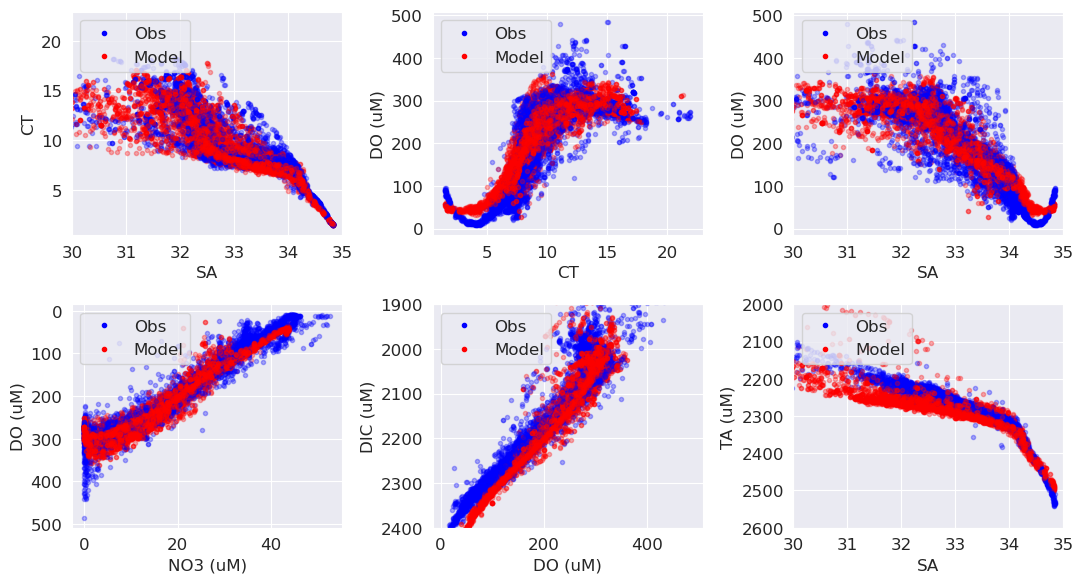

In [10]:
# plot property-to-property

plt.close('all')

fig = plt.figure()
ax_dict = {}

for ii in range(len(vn_list)):
    jj = jj_list[ii]
    if otype == 'ctd':
        ax = fig.add_subplot(1,3,jj)
    else:
        ax = fig.add_subplot(2,3,jj)
        
    ax_dict[ii] = ax
    ax.plot([], [], marker='.', ls='', color='b', label='Obs')
    ax.plot([], [], marker='.', ls='', color='r', label='Model')

    handles, labels = ax.get_legend_handles_labels()
    unique_handles, unique_labels = [], []
    for h, l in zip(handles, labels):
        if l not in unique_labels:
            unique_handles.append(h)
            unique_labels.append(l)
    ax.legend(unique_handles, unique_labels, loc="upper left")

    for year in yr_list:
        print(year)
        # specify input (created by process_multi_bottle.py)
        in_fn = in_dir / ('combined_' + otype + '_' + str(year)+'_' + gtx +'.p')
        df0_dict = pickle.load(open(in_fn, 'rb'))
        for gtxo in df0_dict.keys():
            df0_dict[gtxo] = df0_dict[gtxo][df0_dict[gtxo].source==source]
        # ======== APPLY FILTERS ==================================
        if fil_dict['clean_up']:
            a = df0_dict['obs'].copy()
            if 'otype' == 'bottle':
                mask1 =  pd.isna(a['CT'])| pd.isna(a['SA'])| pd.isna(a['DO (uM)']) |(a['DO (uM)'] < 0) | (a['DO (uM)'] > 650) | (a['NO3 (uM)'] > 55)
                mask2 =  (a['CT'] < 5) & (a['DO (uM)'] > 200)
                mask3 =  (a['CT'] < 7) & (a['DO (uM)'] > 300)
            else:
                mask1 = pd.isna(a['CT'])| pd.isna(a['SA'])| pd.isna(a['DO (uM)']) | (a['DO (uM)'] < 0) | (a['DO (uM)'] > 650)
                mask2 =  (a['CT'] < 5) & (a['DO (uM)'] > 200)
                mask3 =  (a['CT'] < 7) & (a['DO (uM)'] > 300)
            mask = (~mask1) & (~mask2) & (~mask3)
            df0_dict['obs'] = a.loc[mask, :]
            df0_dict[gtx] = df0_dict[gtx].loc[mask, :]  # Apply mask to model as well
        # mask out Salish Fields
        if fil_dict['mask_salish']:
            for gtxo in df0_dict.keys():
                a = df0_dict[gtxo].copy()
                mask1 = (a.lat >= 46) & (a.lat < 49) & (a.lon > -124)
                mask2 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -125)
                mask3 = (a.lat >= 49.5) & (a.lat < 52) & (a.lon > -126)
                mask4 = (a.lat >= 50) & (a.lat < 52) & (a.lon > -128.5)
                mask5 = (a.lat >= 48.5) & (a.lat < 49.5) & (a.lon > -125.5)
                mask6 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -126.5)
                mask7 = (a.lat >= 51) & (a.lat < 52) & (a.lon > -128) & (a.lon < -126.5)
                a = a.loc[(~mask1) & (~mask2) & (~mask3) & (~mask4) & (~mask5) & (~mask6) & (~mask7), :]
                df0_dict[gtxo] = a
        # mask out Coastal Fields
        if fil_dict['mask_coast']:
            for gtxo in df0_dict.keys():
                a = df0_dict[gtxo].copy()
                mask1 = (a.lat >= 47) & (a.lat < 49) & (a.lon > -124)
                mask2 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -125)
                mask = (~mask1) & (~mask2)
                a = a.loc[~mask, :]
                df0_dict[gtxo] = a

        df_dict = df0_dict.copy()

        vn = vn_list[ii]
        if vn == 'SA':
            x = df_dict['obs'][vn].to_numpy()
            y = df_dict['obs']['CT'].to_numpy()
            xx = df_dict[gtx][vn].to_numpy()
            yy = df_dict[gtx]['CT'].to_numpy()
            ax.plot(x,y,marker='.',ls='',color='b', alpha=alpha, label='Obs')
            ax.plot(xx,yy,marker='.',ls='',color='r', alpha=alpha, label='Model')
            ax.set_xlabel(vn)
            ax.set_xlim([30, 35])
            ax.set_ylabel('CT')

        elif vn == 'CT':
            x = df_dict['obs'][vn].to_numpy()
            y = df_dict['obs']['DO (uM)'].to_numpy()
            xx = df_dict[gtx][vn].to_numpy()
            yy = df_dict[gtx]['DO (uM)'].to_numpy()
            ax.plot(x,y,marker='.',ls='',color='b', alpha=alpha, label='Obs')
            ax.plot(xx,yy,marker='.',ls='',color='r', alpha=alpha, label='Model')
            ax.set_xlabel(vn)
            ax.set_ylabel('DO (uM)')
        elif vn == 'DO (uM)':
            x = df_dict['obs']['SA'].to_numpy()
            y = df_dict['obs'][vn].to_numpy()
            xx = df_dict[gtx]['SA'].to_numpy()
            yy = df_dict[gtx][vn].to_numpy()
            ax.plot(x,y,marker='.',ls='',color='b', alpha=alpha, label='Obs')
            ax.plot(xx,yy,marker='.',ls='',color='r', alpha=alpha, label='Model')
            ax.set_xlabel('SA')
            ax.set_xlim([30, 35])
            ax.set_ylabel(vn)
        elif vn == 'NO3 (uM)':
            x = df_dict['obs'][vn].to_numpy()
            y = df_dict['obs']['DO (uM)'].to_numpy()
            xx = df_dict[gtx][vn].to_numpy()
            yy = df_dict[gtx]['DO (uM)'].to_numpy()
            ax.plot(x,y,marker='.',ls='',color='b', alpha=alpha, label='Obs')
            ax.plot(xx,yy,marker='.',ls='',color='r', alpha=alpha, label='Model')
            ax.set_xlabel(vn)
            ax.set_ylabel('DO (uM)')
            ax.invert_yaxis()
        elif vn == 'DIC (uM)':
            x = df_dict['obs']['DO (uM)'].to_numpy()
            y = df_dict['obs'][vn].to_numpy()
            xx = df_dict[gtx]['DO (uM)'].to_numpy()
            yy = df_dict[gtx][vn].to_numpy()
            ax.plot(x,y,marker='.',ls='',color='b', alpha=alpha, label='Obs')
            ax.plot(xx,yy,marker='.',ls='',color='r', alpha=alpha, label='Model')
            ax.set_xlabel('DO (uM)')
            ax.set_ylim([1900, 2400])
            ax.set_ylabel(vn)
        elif vn == 'TA (uM)':
            x = df_dict['obs']['SA'].to_numpy()
            y = df_dict['obs'][vn].to_numpy()
            xx = df_dict[gtx]['SA'].to_numpy()
            yy = df_dict[gtx][vn].to_numpy()
            ax.plot(x,y,marker='.',ls='',color='b', alpha=alpha, label='Obs')
            ax.plot(xx,yy,marker='.',ls='',color='r', alpha=alpha, label='Model')
            ax.set_ylim([2000, 2600])
            ax.set_xlim([30, 35])
            ax.set_xlabel('SA')
            ax.set_ylabel(vn)


        # ax.text(.05,.9,vn,transform=ax.transAxes, fontweight='bold')
        # ax.axis([lim_dict[vn][0], lim_dict[vn][1], lim_dict[vn][0], lim_dict[vn][1]])
        # ax.plot([lim_dict[vn][0], lim_dict[vn][1]], [lim_dict[vn][0], lim_dict[vn][1]],'-g')
        ax.grid(True)
        if vn == 'TA (uM)' or vn == 'DIC (uM)':
            ax.invert_yaxis()


fig.tight_layout()

plt.savefig(out_dir / (ff_str + '_' + 'relationship' + '.png'))